In [36]:
# Imports
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
from scipy import stats
import seaborn as sns
import matplotlib


In [37]:
#Getting the Average success values from the Rag and No Rag runs
df = pd.read_csv('all_vision_kernels_vitis.csv')


# Formatting the successes and model names
df['latency'] = pd.to_numeric(df['latency'], errors='coerce')
df['model'] = df['model'].str.split('/').str[-1]


df['compilation_failed'] = df['compilation_status'] == 'failed'
df['mismatched_only'] = (df['outputs_match'] == 'mismatch') & (df['compilation_status'] != 'failed')


# Getting success and failure categories
# Make sure csim/csynth columns are numeric before aggregate calculations
df['csim_success'] = pd.to_numeric(df['csim_success'], errors='coerce').fillna(0).astype(int)
df['csynth_success'] = pd.to_numeric(df['csynth_success'], errors='coerce').fillna(0).astype(int)

df['csynth_fail_csim_pass'] = ((df['csim_success'] == 1) & (df['csynth_success'] == 0)).astype(int)
df['compiled_but_mismatched'] = ((~df['compilation_failed']) & (df['outputs_match'] == 'mismatch')).astype(int)

total_tests = len(df)
print(f'Total rows: {total_tests}')

# Group by model and RAG to compute correct per-group percentages
grouped = df.groupby(['model', 'RAG']).agg(
    total_tests=('model', 'count'),
    csynth_pass=('csynth_success', 'sum'),
    csynth_fail_csim_pass=('csynth_fail_csim_pass', 'sum'),
    compiled_but_mismatched=('compiled_but_mismatched', 'sum'),
    compilation_failed=('compilation_failed', 'sum')
).reset_index()

grouped['csynth_pass_pct'] = grouped['csynth_pass'] / grouped['total_tests'] * 100
grouped['csynth_fail_csim_pass_pct'] = grouped['csynth_fail_csim_pass'] / grouped['total_tests'] * 100
grouped['compiled_but_mismatched_pct'] = grouped['compiled_but_mismatched'] / grouped['total_tests'] * 100
grouped['compilation_failed_pct'] = grouped['compilation_failed'] / grouped['total_tests'] * 100

# Build the success summary DataFrame using group-level percentages
average_success = grouped[['model', 'RAG', 'csynth_pass_pct']].rename(columns={'csynth_pass_pct': 'csynth_success'})
average_success_unsort = average_success.copy()

#Averaging the success rates
# print(average_success_unsort)
# print(avg_success_norag)

#Get Average Price per Call in each Rag v NoRag run
model_costs_data_norag = {
    'model': ['gemini-2.5-flash', 'deepseek-chat-v3-0324', 'deepseek-r1-0528', 'gpt-4.1-mini', 'grok-code-fast-1',  
              'qwen3-coder', 'gpt-5', 'grok-4', 'gemini-2.5-pro', 'claude-sonnet-4.5'],
    'Base_Cost_Per_Run': [0.25, 0.08, 0.88, 0.12, 0.15, 0.08, 2.66, 6.07, 4.48, 1.92],
    'Cost_STD': [0.16, 0.05, 0.46, 0.06, 0.06, 0.07, 1.05, 4.12, 2.61, 1.16]
}
costs_norag = pd.DataFrame(model_costs_data_norag).set_index('model')

model_costs_data_rag = {
    'model': ['gemini-2.5-flash', 'deepseek-chat-v3-0324', 'deepseek-r1-0528', 'gpt-4.1-mini', 'grok-code-fast-1',  
              'qwen3-coder', 'gpt-5', 'grok-4', 'gemini-2.5-pro', 'claude-sonnet-4.5'],
    'Base_Cost_Per_Run': [0.22, 0.12, 0.92, 0.17, 0.18, 0.09, 2.93, 7.90, 6.13, 1.92]
}
costs_rag = pd.DataFrame(model_costs_data_rag).set_index('model')


# costs_rag.rename(columns={'Model': 'model'}, inplace=True)
# costs_norag.rename(columns={'Model': 'model'}, inplace=True)

avg_success_rag = average_success[average_success['RAG'] == 'rag'].copy()
avg_success_norag = average_success[average_success['RAG'] == 'no_rag'].copy()

plot_df_rag = avg_success_rag.merge(
    costs_rag, 
    on='model', 
    how='left'
).rename(columns={'Base_Cost_Per_Run': 'Cost_Per_Run'})
plot_df_norag = avg_success_norag.merge(
    costs_norag, 
    on='model', 
    how='left'
).rename(columns={'Base_Cost_Per_Run': 'Cost_Per_Run'})

# 4. Combine RAG and No RAG data into the final plotting DataFrame
final_plot_df = pd.concat([plot_df_rag, plot_df_norag], ignore_index=True)

# 5. Clean up final columns: rename csim_success for clarity
final_plot_df.rename(
    columns={'csynth_success': 'Average Success Rate (%)'}, 
    inplace=True
)

plot_df_norag.rename(
    columns={'csynth_success': 'Average Success Rate (%)'}, 
    inplace=True
)



Total rows: 5565


In [38]:
# Verify the corrected category counts and percentages
failure_analysis = grouped.copy()
failure_analysis['model'] = failure_analysis['model'].str.split('/').str[-1]

# Keep only the key percentages for the requested categories
failure_analysis = failure_analysis[['model', 'RAG', 'total_tests',
                                     'csynth_pass_pct',
                                     'csynth_fail_csim_pass_pct',
                                     'compiled_but_mismatched_pct',
                                     'compilation_failed_pct']]

failure_analysis = failure_analysis.rename(columns={
    'csynth_pass_pct': 'csynth_success_pct',
    'csynth_fail_csim_pass_pct': 'csynth_fail_csim_pass_pct',
    'compiled_but_mismatched_pct': 'compiled_but_mismatched_pct',
    'compilation_failed_pct': 'compilation_failed_pct'
})

display(failure_analysis)

overall_counts = grouped[['csynth_pass', 'csynth_fail_csim_pass', 'compiled_but_mismatched', 'compilation_failed']].sum()
overall_pct = overall_counts / total_tests * 100
print('\nOverall counts:')
print(overall_counts.to_dict())
print('\nOverall percentages:')
print(overall_pct.to_dict())


,model,RAG,total_tests,csynth_success_pct,csynth_fail_csim_pass_pct,compiled_but_mismatched_pct,compilation_failed_pct
0,claude-sonnet-4.5,no_rag,1900,38.315789,2.736842,16.842105,42.105263
1,gemini-2.5-flash,no_rag,1765,26.402266,3.966006,16.033994,53.597734
2,qwen3-coder,no_rag,1900,33.263158,2.894737,17.473684,46.526316



Overall counts:
{'csynth_pass': 1826, 'csynth_fail_csim_pass': 177, 'compiled_but_mismatched': 935, 'compilation_failed': 2630}

Overall percentages:
{'csynth_pass': 32.81221922731356, 'csynth_fail_csim_pass': 3.1805929919137466, 'compiled_but_mismatched': 16.801437556154536, 'compilation_failed': 47.2596585804133}


               model     RAG  csim_success
0  claude-sonnet-4.5  no_rag     38.315789
1   gemini-2.5-flash  no_rag     26.402266
2        qwen3-coder  no_rag     33.263158


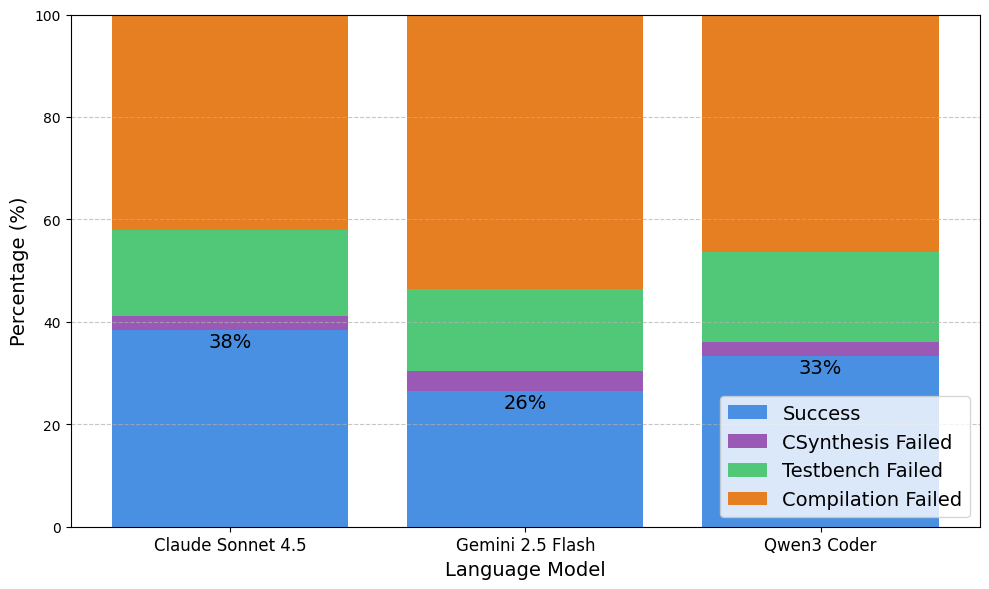

In [44]:
# Creating the Plots with failure breakdown stacked on top of success
# Filter failure analysis for no_rag only
failure_norag = failure_analysis[failure_analysis['RAG'] == 'no_rag'].copy()
# Get success rate data for no_rag using per-group totals
df_plot_norag = grouped[['model', 'RAG', 'csynth_pass_pct']].rename(columns={'csynth_pass_pct': 'csim_success'})
df_plot_norag = df_plot_norag[df_plot_norag['RAG'] == 'no_rag'].copy()
print(df_plot_norag)

# Rename models for better display
model_names = {
    "gpt-4.1-mini": "GPT-4.1 mini",
    "grok-code-fast-1": "Grok Code Fast 1",
    "gemini-2.5-flash": "Gemini 2.5 Flash",
    "deepseek-chat-v3-0324": "Deepseek V3",
    "deepseek-r1-0528": "Deepseek R1",
    "qwen3-coder": "Qwen3 Coder",
    "grok-4": "Grok 4",
    "gemini-2.5-pro": "Gemini 2.5 Pro",
    "claude-sonnet-4.5": "Claude Sonnet 4.5",
    "gpt-5": "GPT 5"
}

# Merge failure data with success rates
failure_norag['model'] = failure_norag['model'].map(model_names)
df_plot_norag['model'] = df_plot_norag['model'].map(model_names)

# Merge on model name to align data
merged_data = pd.merge(df_plot_norag, failure_norag, on='model', how='left')
merged_data = merged_data.set_index('model')

# --- Visualization ---
plt.figure(figsize=(10, 6))
failure_analysis['model'] = failure_analysis['model'].map(model_names)

# Create stacked bar chart: Blue (success) + Green (csynth fail) + Orange (both fail)
x = range(len(merged_data))
success_pct = failure_analysis['csynth_success_pct'].values
csynth_fail_pct = failure_analysis['csynth_fail_csim_pass_pct'].values
compile_fail_pct = failure_analysis['compilation_failed_pct'].values
mismatched_pct = failure_analysis['compiled_but_mismatched_pct']

p1 = plt.bar(x, success_pct, label='Success', color="#4A90E2")
p2 = plt.bar(x, csynth_fail_pct, bottom=success_pct, label='CSynthesis Failed', color="#9B59B6")
p3 = plt.bar(x, mismatched_pct, bottom=success_pct + csynth_fail_pct, label='Testbench Failed', color='#50C878')
p4 = plt.bar(x, compile_fail_pct, bottom=success_pct + csynth_fail_pct+ mismatched_pct, label='Compilation Failed', color="#E67E22")

for rect, v in zip(p1, success_pct):
    height = rect.get_height()
    plt.text(
        rect.get_x() + rect.get_width() / 2,
        height - 4,
        f"{v:.0f}%",
        ha='center',
        va='bottom',
        fontsize=14
    )


# Add title and labels
# plt.title(f'Pass and Fail Rates', fontsize=14)
plt.ylabel('Percentage (%)', fontsize=14)
plt.xlabel('Language Model', fontsize=14)
plt.ylim(0, 100)
plt.xticks(x, merged_data.index, ha='center', fontsize=12)
plt.legend(loc='lower right', fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig("success_fail_rates_5x5.pdf", dpi=300, bbox_inches='tight')   
plt.show()


                            model  total_kernels  kernels_passed  \
0  deepseek/deepseek-chat-v3-0324             55               2   

   pass_percentage  
0         3.636364  

Total unique kernels per model: [55]


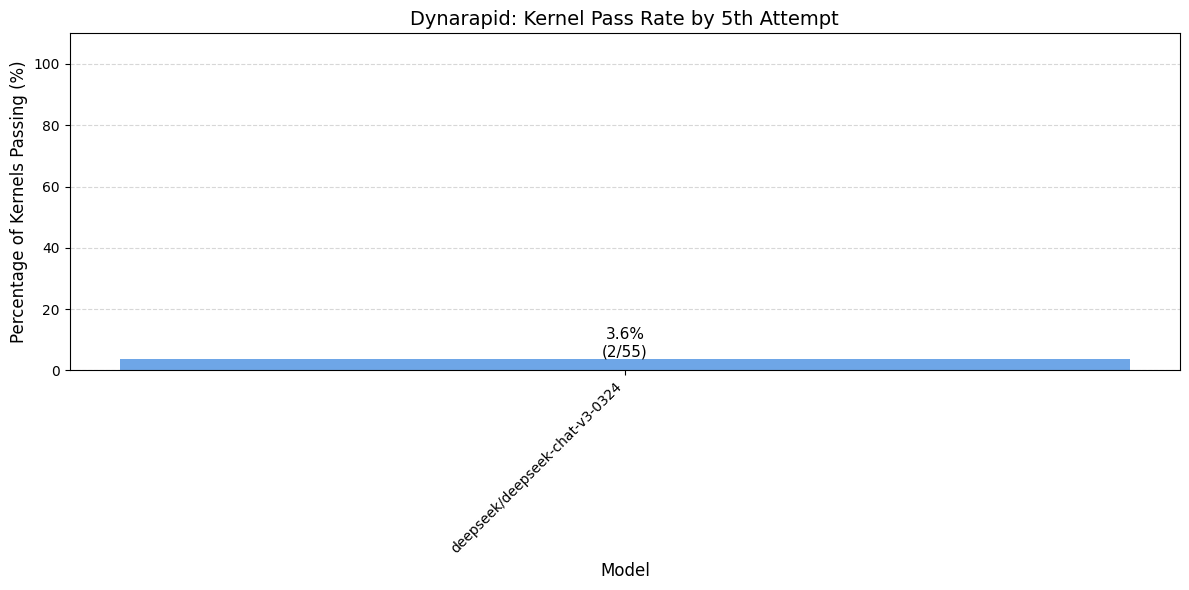

In [63]:
df_dyna = pd.read_csv('dynarapid_results.csv')

df_dyna['csim_success'] = df_dyna['matched'] == 'match'
df_dyna['csim_success'] = pd.to_numeric(df_dyna['csim_success'], errors='coerce').fillna(0).astype(int)
df_dyna['success'] = df_dyna['has_dcp'] & df_dyna['csim_success']
df_dyna['success'] = pd.to_numeric(df_dyna['success'], errors='coerce').fillna(0).astype(int)

# Compute cumulative max of success within each (model, kernel) group
df_dyna['success_count'] = df_dyna.groupby(['model', 'kernel'])['success'].cummax()

# Get success status by the 5th attempt for each (model, kernel) pair
# Group by model and kernel, take the first 5 rows, and check if success_count is 1 by attempt 5
df_by_attempt = df_dyna.groupby(['model', 'kernel']).head(5).reset_index(drop=True)
kernel_success_by_5 = df_by_attempt.groupby(['model', 'kernel'])['success_count'].max().reset_index()
kernel_success_by_5 = kernel_success_by_5.rename(columns={'success_count': 'passed_by_5'})

# Count kernels that passed by attempt 5 per model
kernels_passed = kernel_success_by_5.groupby('model').agg(
    total_kernels=('kernel', 'count'),
    kernels_passed=('passed_by_5', 'sum')
).reset_index()

kernels_passed['pass_percentage'] = (kernels_passed['kernels_passed'] / kernels_passed['total_kernels']) * 100

print(kernels_passed)
print(f'\nTotal unique kernels per model: {kernels_passed["total_kernels"].unique()}')

# Create bar plot
fig, ax = plt.subplots(figsize=(12, 6))
x_pos = range(len(kernels_passed))
bars = ax.bar(x_pos, kernels_passed['pass_percentage'], color='#4A90E2', alpha=0.8)

# Add percentage labels on bars
for bar, pct in zip(bars, kernels_passed['pass_percentage']):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{pct:.1f}%\n({int(kernels_passed.iloc[x_pos.index(bar.get_x() + bar.get_width()/2.)]["kernels_passed"])}/55)',
            ha='center', va='bottom', fontsize=11)

ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('Percentage of Kernels Passing (%)', fontsize=12)
ax.set_title('Dynarapid: Kernel Pass Rate by 5th Attempt', fontsize=14)
ax.set_xticks(x_pos)
ax.set_xticklabels(kernels_passed['model'], rotation=45, ha='right')
ax.set_ylim(0, 110)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('dynarapid_kernel_pass_rate.pdf', dpi=300, bbox_inches='tight')
plt.show()
